<a href="https://colab.research.google.com/github/gitenterpriseengineer/aiml-program/blob/main/Full_Code_SuperKart_Model_Deployment_Notebook_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [ ]:
#Installing the libraries with the specified versions
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.4 huggingface_hub==0.34.0 -q

**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [4]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# for hugging face space authentication to upload files
from huggingface_hub import login, HfApi

# **Loading the dataset**

In [9]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd # Import pandas here

# Adjust the path to your dataset in Google Drive
# For example, if your file is in 'My Drive/data/sales_data.csv'
# data = pd.read_csv('/content/drive/MyDrive/data/sales_data.csv')
data = pd.read_csv('/content/drive/MyDrive/SuperKart.csv') # Assuming this is the dataset name

Mounted at /content/drive


# **Data Overview**

In [8]:
# Display the first 5 rows of the dataset
print("First 5 rows of the dataset:")
display(data.head())

# Display the shape of the dataset
print("\nShape of the dataset (rows, columns):")
print(data.shape)

# Display information about the dataset (data types, non-null values)
print("\nInformation about the dataset:")
data.info()

# Display descriptive statistics of the dataset
print("\nDescriptive statistics of the dataset:")
display(data.describe().T)

First 5 rows of the dataset:


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36



Shape of the dataset (rows, columns):
(8763, 12)

Information about the dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1

,count,mean,std,min,25%,50%,75%,max
Product_Weight,8763.0,12.653792,2.217320,4.000,11.150,12.660,14.180,22.000
Product_Allocated_Area,8763.0,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_MRP,8763.0,147.032539,30.694110,31.000,126.160,146.740,167.585,266.000
Store_Establishment_Year,8763.0,2002.032751,8.388381,1987.000,1998.000,2009.000,2009.000,2009.000
Product_Store_Sales_Total,8763.0,3464.003640,1065.630494,33.000,2761.715,3452.340,4145.165,8000.000


# **Exploratory Data Analysis (EDA)**

## Univariate Analysis


Analyzing numerical column: Product_Weight


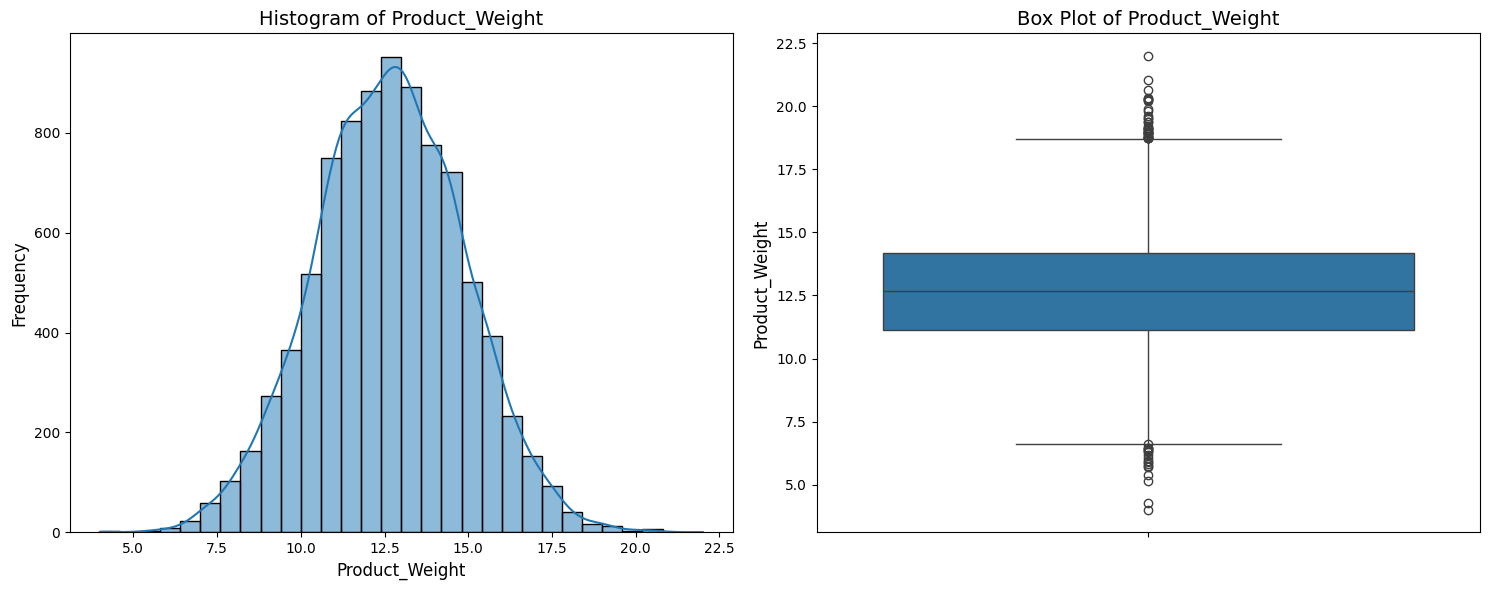

Descriptive statistics for Product_Weight:
count    8763.000000
mean       12.653792
std         2.217320
min         4.000000
25%        11.150000
50%        12.660000
75%        14.180000
max        22.000000
Name: Product_Weight, dtype: float64
Skewness for Product_Weight: 0.0175
Kurtosis for Product_Weight: 0.0046

Analyzing numerical column: Product_Allocated_Area


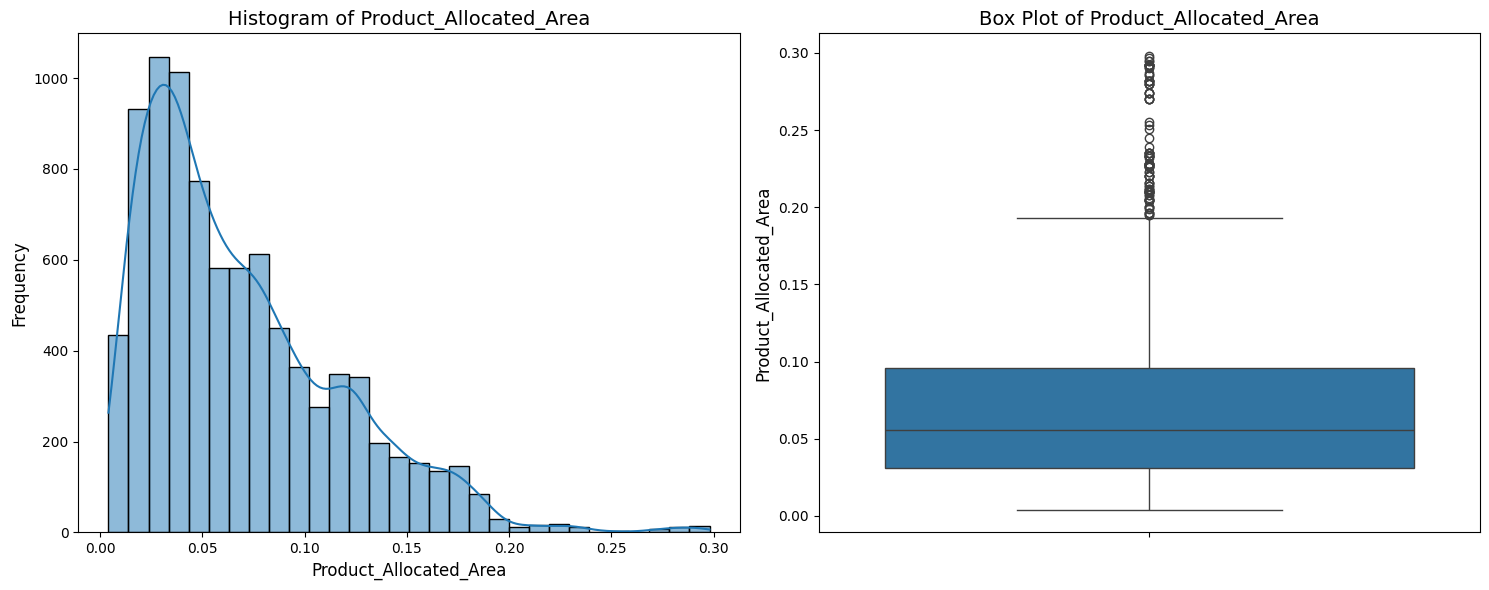

Descriptive statistics for Product_Allocated_Area:
count    8763.000000
mean        0.068786
std         0.048204
min         0.004000
25%         0.031000
50%         0.056000
75%         0.096000
max         0.298000
Name: Product_Allocated_Area, dtype: float64
Skewness for Product_Allocated_Area: 1.1281
Kurtosis for Product_Allocated_Area: 1.2931

Analyzing numerical column: Product_MRP


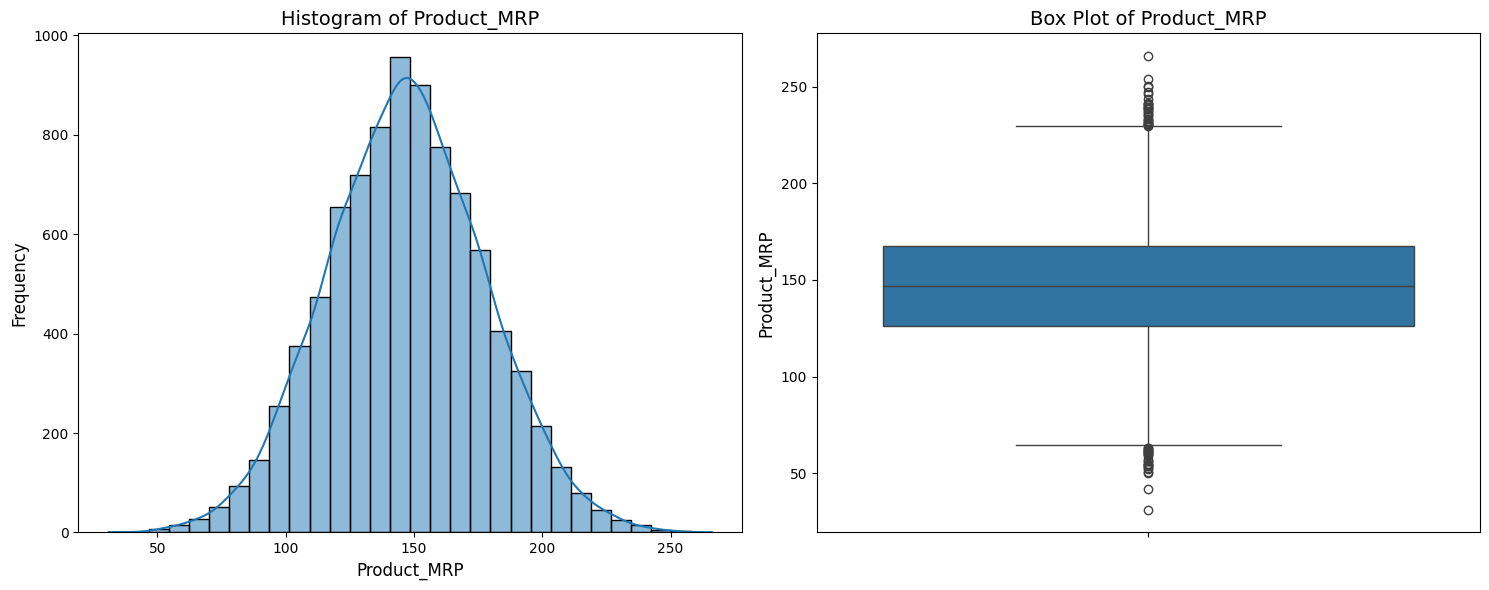

Descriptive statistics for Product_MRP:
count    8763.000000
mean      147.032539
std        30.694110
min        31.000000
25%       126.160000
50%       146.740000
75%       167.585000
max       266.000000
Name: Product_MRP, dtype: float64
Skewness for Product_MRP: 0.0365
Kurtosis for Product_MRP: -0.0116

Analyzing numerical column: Store_Establishment_Year


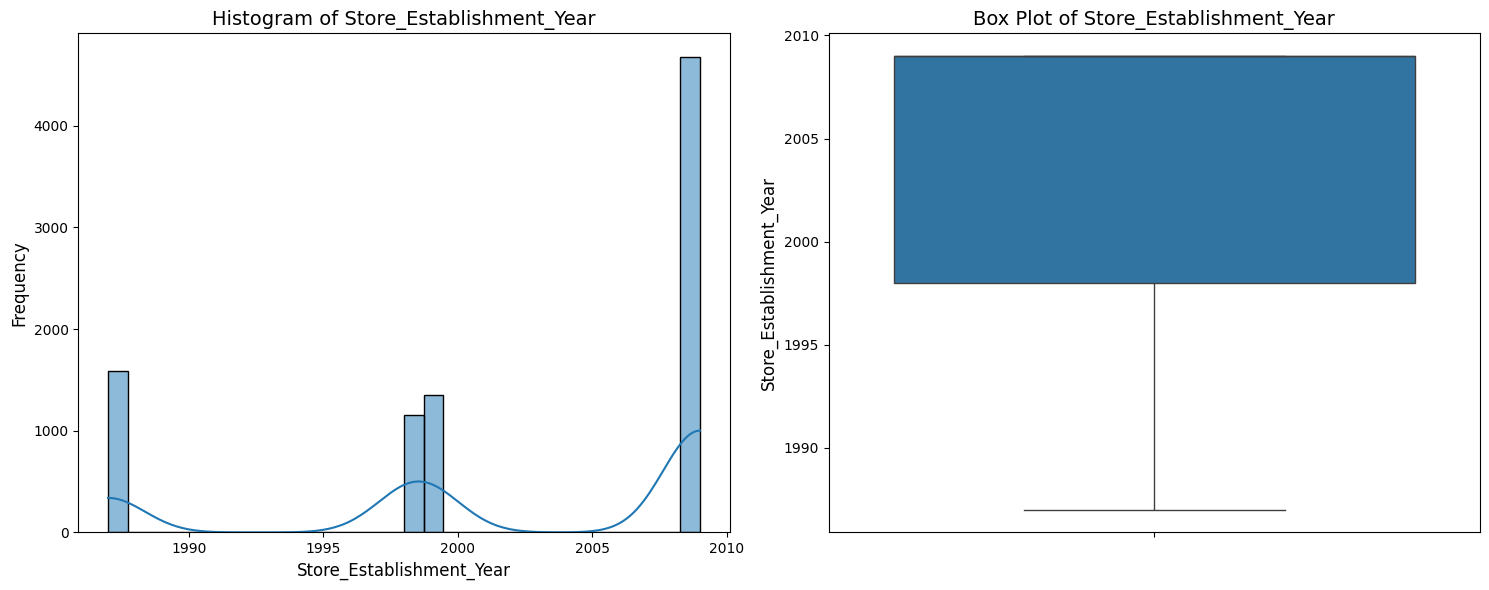

Descriptive statistics for Store_Establishment_Year:
count    8763.000000
mean     2002.032751
std         8.388381
min      1987.000000
25%      1998.000000
50%      2009.000000
75%      2009.000000
max      2009.000000
Name: Store_Establishment_Year, dtype: float64
Skewness for Store_Establishment_Year: -0.7581
Kurtosis for Store_Establishment_Year: -0.8689

Analyzing numerical column: Product_Store_Sales_Total


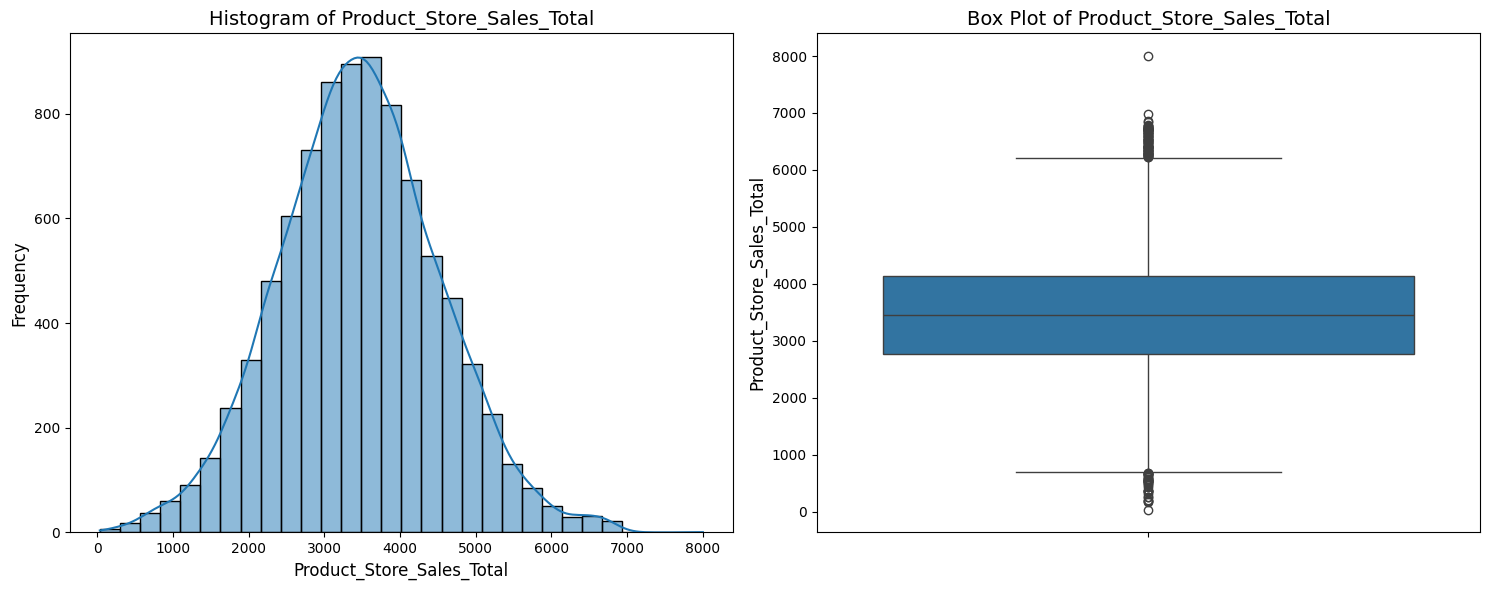

Descriptive statistics for Product_Store_Sales_Total:
count    8763.000000
mean     3464.003640
std      1065.630494
min        33.000000
25%      2761.715000
50%      3452.340000
75%      4145.165000
max      8000.000000
Name: Product_Store_Sales_Total, dtype: float64
Skewness for Product_Store_Sales_Total: 0.0920
Kurtosis for Product_Store_Sales_Total: 0.1524


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Re-load the data to ensure it's defined in this cell's scope
data = pd.read_csv('/content/drive/MyDrive/SuperKart.csv')

numerical_cols = ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year', 'Product_Store_Sales_Total']

for col in numerical_cols:
    print(f"\nAnalyzing numerical column: {col}")
    plt.figure(figsize=(15, 6))

    # Histogram with KDE
    plt.subplot(1, 2, 1)
    sns.histplot(data[col], kde=True, bins=30)
    plt.title(f'Histogram of {col}', fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)

    # Box plot
    plt.subplot(1, 2, 2)
    sns.boxplot(y=data[col])
    plt.title(f'Box Plot of {col}', fontsize=14)
    plt.ylabel(col, fontsize=12)

    plt.tight_layout()
    plt.show()

    # Calculate and print descriptive statistics
    print(f"Descriptive statistics for {col}:\n{data[col].describe()}")

    # Calculate and print skewness
    print(f"Skewness for {col}: {data[col].skew():.4f}")

    # Calculate and print kurtosis
    print(f"Kurtosis for {col}: {data[col].kurt():.4f}")

## Bivariate Analysis


--- Bivariate Analysis ---

1. Correlation Matrix of Numerical Features:


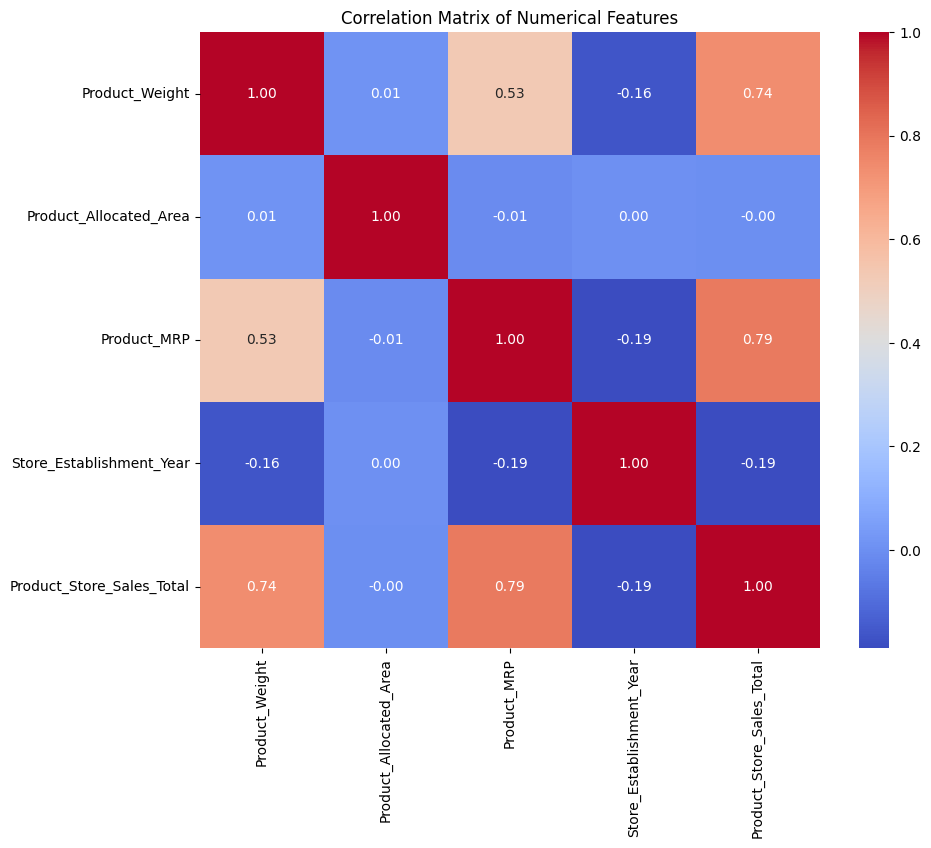


2. Scatter Plots of Numerical Features vs. Product_Store_Sales_Total:


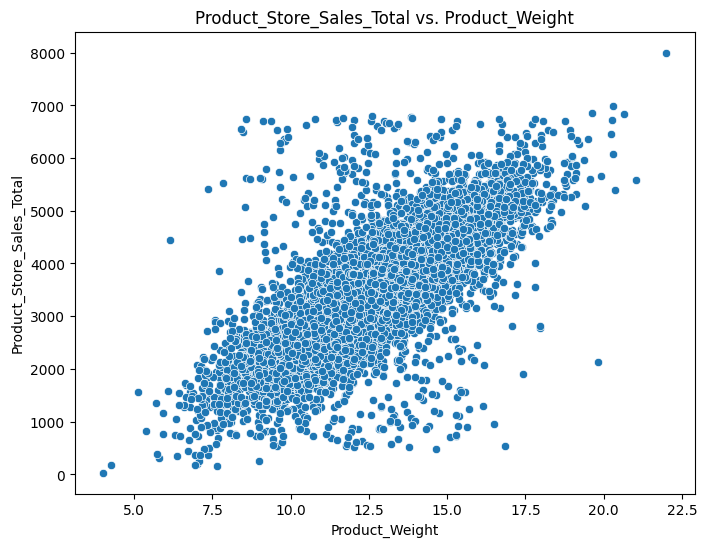

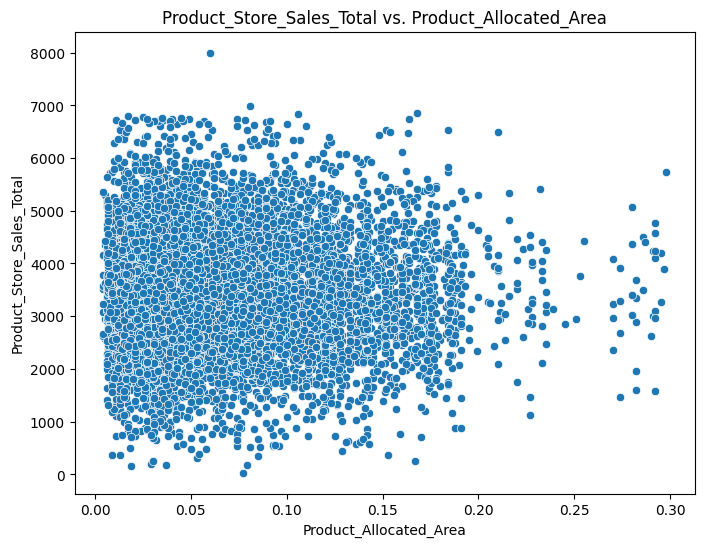

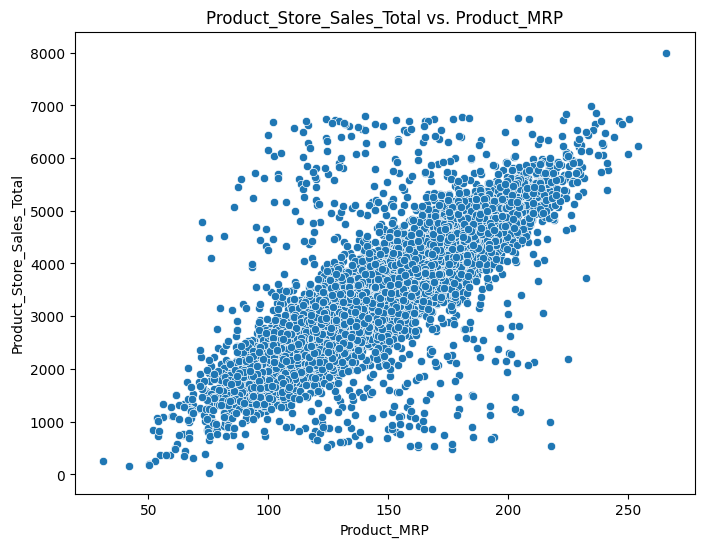

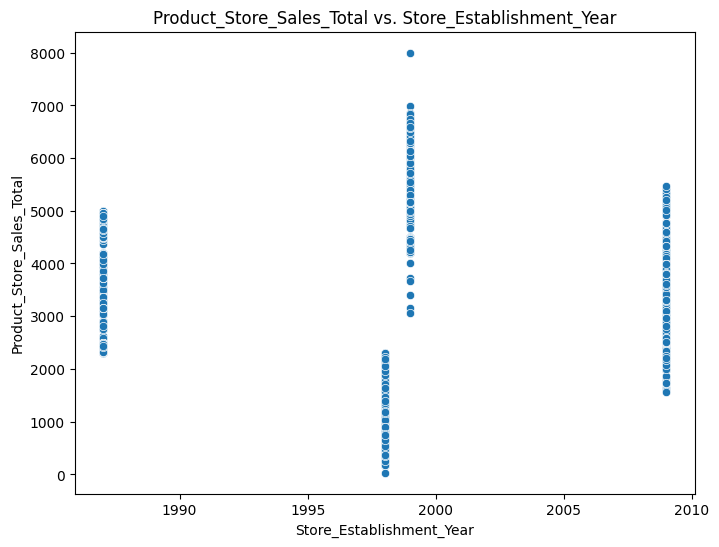


3. Box Plots of Categorical Features vs. Product_Store_Sales_Total:


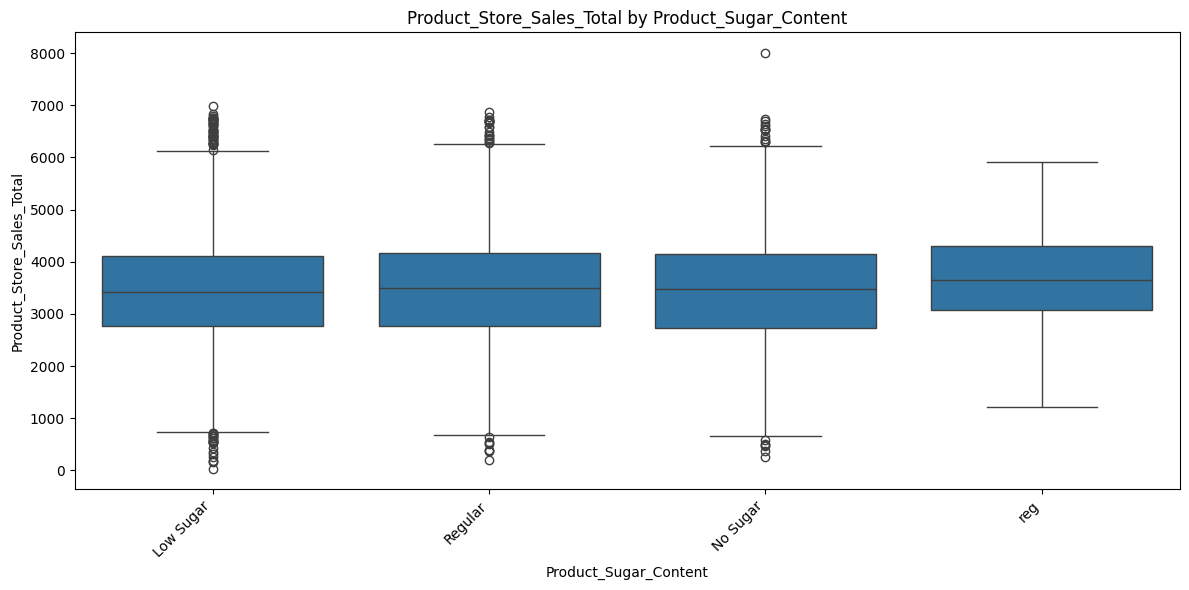

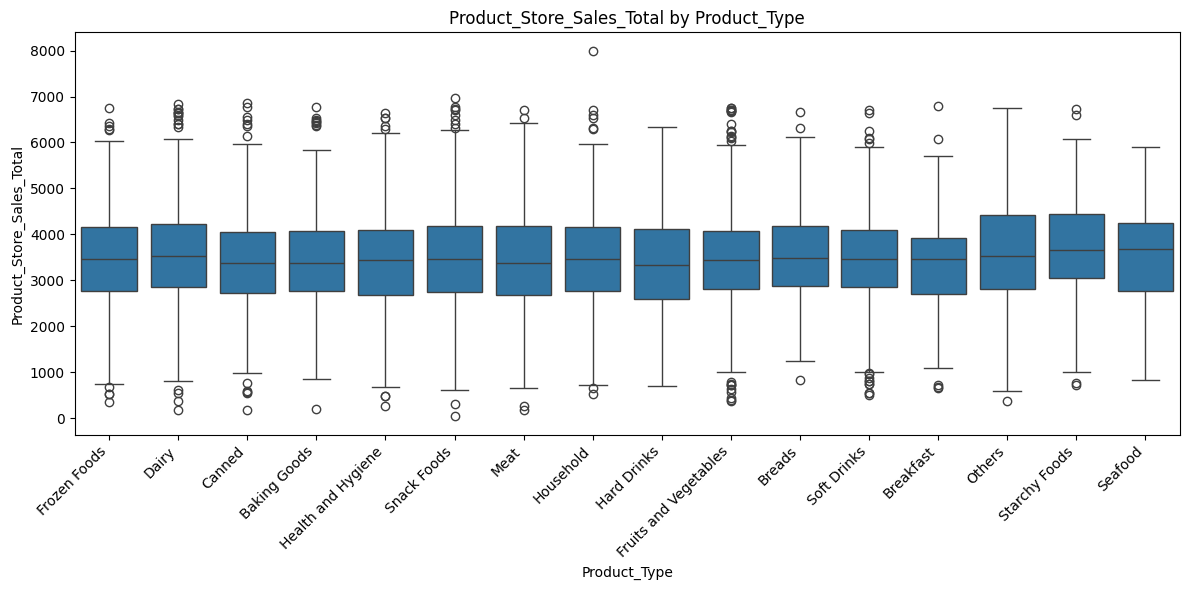

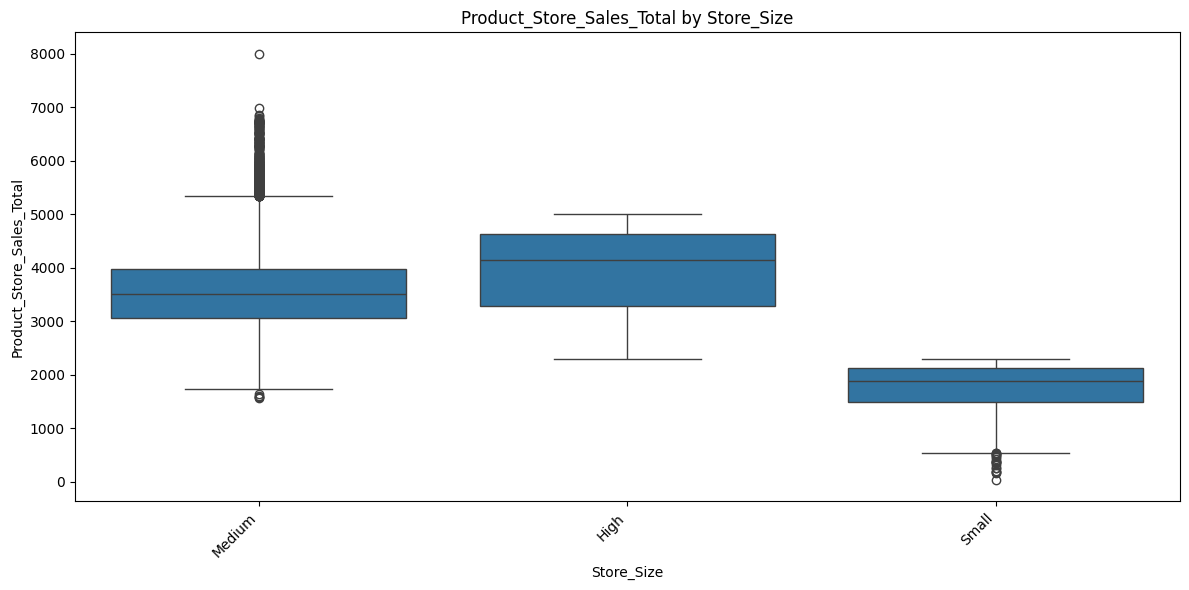

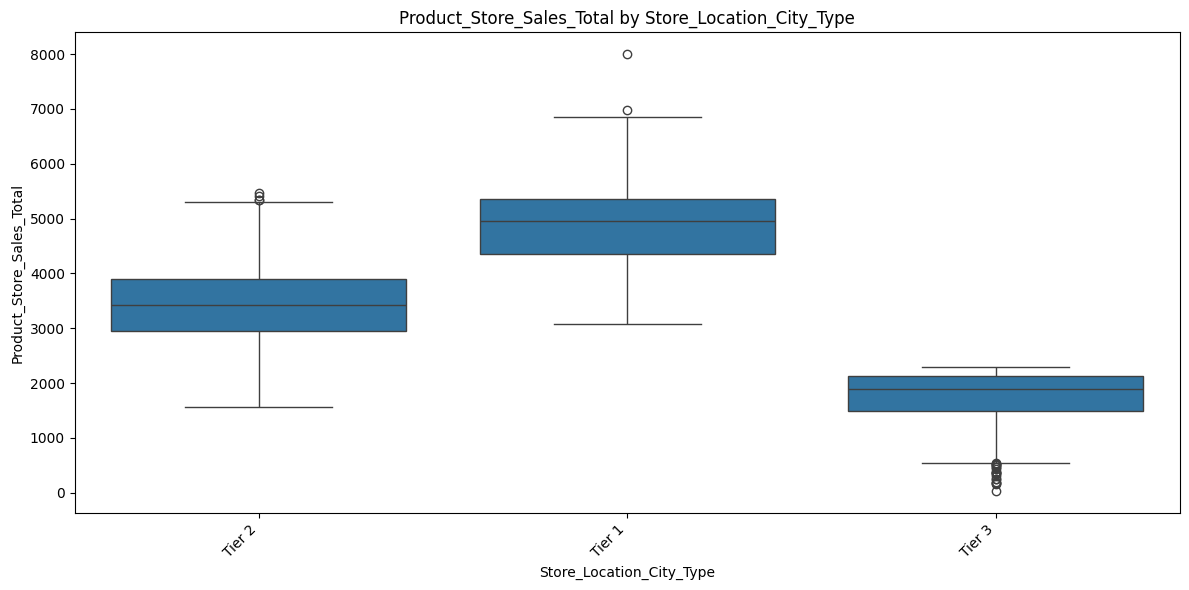

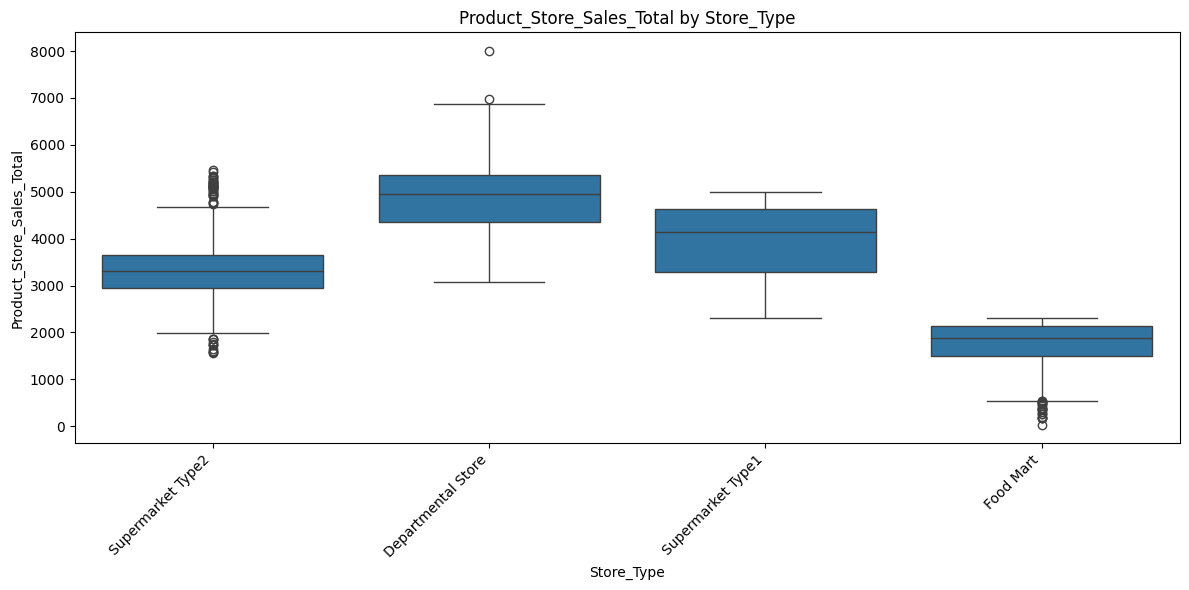

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure 'data' DataFrame is available
# If this cell is run independently, data might need to be reloaded.
# For continuous execution after previous cells, 'data' should already be in scope.
try:
    if 'data' not in locals() or data.empty:
        data = pd.read_csv('/content/drive/MyDrive/SuperKart.csv')
except FileNotFoundError:
    print("Data file not found. Please ensure '/content/drive/MyDrive/SuperKart.csv' exists and Google Drive is mounted.")
except Exception as e:
    print(f"An error occurred while loading data: {e}")

# --- Bivariate Analysis ---

print("\n--- Bivariate Analysis ---")

# 1. Correlation Matrix for Numerical Features
print("\n1. Correlation Matrix of Numerical Features:")
numerical_cols = ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year', 'Product_Store_Sales_Total']
plt.figure(figsize=(10, 8))
sns.heatmap(data[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

# 2. Scatter plots for Numerical Features vs. Target Variable (Product_Store_Sales_Total)
print("\n2. Scatter Plots of Numerical Features vs. Product_Store_Sales_Total:")
for col in ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year']:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=data[col], y=data['Product_Store_Sales_Total'])
    plt.title(f'Product_Store_Sales_Total vs. {col}')
    plt.xlabel(col)
    plt.ylabel('Product_Store_Sales_Total')
    plt.show()

# 3. Box plots for Categorical Features vs. Target Variable (Product_Store_Sales_Total)
print("\n3. Box Plots of Categorical Features vs. Product_Store_Sales_Total:")
categorical_cols_for_bivariate = ['Product_Sugar_Content', 'Product_Type', 'Store_Size', 'Store_Location_City_Type', 'Store_Type']

for col in categorical_cols_for_bivariate:
    plt.figure(figsize=(12, 6))
    sns.boxplot(x=data[col], y=data['Product_Store_Sales_Total'])
    plt.title(f'Product_Store_Sales_Total by {col}')
    plt.xlabel(col)
    plt.ylabel('Product_Store_Sales_Total')
    plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
    plt.tight_layout()
    plt.show()

# **Data Preprocessing**

In [11]:
print("--- Data Preprocessing ---")

# Ensure 'data' DataFrame is reset to original state from CSV
# This is necessary because 'Store_Establishment_Year' might have been dropped in a previous incomplete run.
try:
    data = pd.read_csv('/content/drive/MyDrive/SuperKart.csv')
    print("Data reloaded successfully for preprocessing.")
except FileNotFoundError:
    print("Error: Data file not found. Please ensure '/content/drive/MyDrive/SuperKart.csv' exists and Google Drive is mounted.")
    raise # Re-raise the exception to stop further execution
except Exception as e:
    print(f"An error occurred while reloading data: {e}")
    raise # Re-raise the exception

# 1. Handle inconsistency in 'Product_Sugar_Content'
print("\nOriginal unique values for Product_Sugar_Content:", data['Product_Sugar_Content'].unique())
data['Product_Sugar_Content'] = data['Product_Sugar_Content'].replace({'reg': 'Regular'})
print("Corrected unique values for Product_Sugar_Content:", data['Product_Sugar_Content'].unique())

# 2. Feature Engineering: Create 'Store_Age'
# Assuming current year is 2023 for age calculation
data['Store_Age'] = 2023 - data['Store_Establishment_Year']
print("\nCreated 'Store_Age' feature.")

# 3. Drop identifier columns and the original 'Store_Establishment_Year'
data.drop(columns=['Product_Id', 'Store_Id', 'Store_Establishment_Year'], inplace=True)
print("Dropped 'Product_Id', 'Store_Id', and 'Store_Establishment_Year' columns.")

print("\nData preprocessing complete. Here's the updated dataset head and info:")
display(data.head())
data.info()

--- Data Preprocessing ---
Data reloaded successfully for preprocessing.

Original unique values for Product_Sugar_Content: ['Low Sugar' 'Regular' 'No Sugar' 'reg']
Corrected unique values for Product_Sugar_Content: ['Low Sugar' 'Regular' 'No Sugar']

Created 'Store_Age' feature.
Dropped 'Product_Id', 'Store_Id', and 'Store_Establishment_Year' columns.

Data preprocessing complete. Here's the updated dataset head and info:


,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Store_Age
0,12.66,Low Sugar,0.027,Frozen Foods,117.08,Medium,Tier 2,Supermarket Type2,2842.40,14
1,16.54,Low Sugar,0.144,Dairy,171.43,Medium,Tier 1,Departmental Store,4830.02,24
2,14.28,Regular,0.031,Canned,162.08,High,Tier 2,Supermarket Type1,4130.16,36
3,12.10,Low Sugar,0.112,Baking Goods,186.31,High,Tier 2,Supermarket Type1,4132.18,36
4,9.57,No Sugar,0.010,Health and Hygiene,123.67,Small,Tier 3,Food Mart,2279.36,25


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Weight             8763 non-null   float64
 1   Product_Sugar_Content      8763 non-null   object 
 2   Product_Allocated_Area     8763 non-null   float64
 3   Product_Type               8763 non-null   object 
 4   Product_MRP                8763 non-null   float64
 5   Store_Size                 8763 non-null   object 
 6   Store_Location_City_Type   8763 non-null   object 
 7   Store_Type                 8763 non-null   object 
 8   Product_Store_Sales_Total  8763 non-null   float64
 9   Store_Age                  8763 non-null   int64  
dtypes: float64(4), int64(1), object(5)
memory usage: 684.7+ KB


# **Model Building**

## Define functions for Model Evaluation

In [12]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

The ML models to be built can be any two out of the following:
1. Decision Tree
2. Bagging
3. Random Forest
4. AdaBoost
5. Gradient Boosting
6. XGBoost

In [13]:
# Essential imports for data splitting, preprocessing, and model building
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Imports for model evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

import matplotlib.pyplot as plt
import seaborn as sns


In [14]:
# Reload the data DataFrame to ensure it's available for model building
import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/SuperKart.csv')
print("Data DataFrame reloaded successfully.")

Data DataFrame reloaded successfully.


In [15]:
# Separate features (X) and target (y)
X = data.drop('Product_Store_Sales_Total', axis=1)
y = data['Product_Store_Sales_Total']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

# Identify numerical and categorical features for preprocessing
numerical_features = X.select_dtypes(include=['float64', 'int64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

# Create a preprocessor using ColumnTransformer
# Numerical features will be scaled using StandardScaler
# Categorical features will be one-hot encoded using OneHotEncoder
preprocessor = make_column_transformer(
    (StandardScaler(), numerical_features),
    (OneHotEncoder(handle_unknown='ignore'), categorical_features)
)

# 1. Random Forest Regressor Pipeline
# Combine preprocessing with the Random Forest model
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

# 2. XGBoost Regressor Pipeline
# Combine preprocessing with the XGBoost model
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42))
])

print("\nPipelines for Random Forest and XGBoost Regressors created successfully.")

# Train the initial models to get a baseline performance
print("\nTraining initial Random Forest model...")
rf_pipeline.fit(X_train, y_train)
print("Initial Random Forest model trained.")

print("\nTraining initial XGBoost model...")
xgb_pipeline.fit(X_train, y_train)
print("Initial XGBoost model trained.")

# Evaluate initial models
print("\nInitial Random Forest Model Performance:")
display(model_performance_regression(rf_pipeline, X_train, y_train))

print("\nInitial XGBoost Model Performance:")
display(model_performance_regression(xgb_pipeline, X_train, y_train))


X_train shape: (7010, 11)
X_test shape: (1753, 11)
y_train shape: (7010,)
y_test shape: (1753,)

Pipelines for Random Forest and XGBoost Regressors created successfully.

Training initial Random Forest model...
Initial Random Forest model trained.

Training initial XGBoost model...
Initial XGBoost model trained.

Initial Random Forest Model Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,103.018239,28.145401,0.990642,0.990627,0.011663



Initial XGBoost Model Performance:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,170.795555,96.866079,0.974277,0.974236,0.037811


# **Model Performance Improvement - Hyperparameter Tuning**

In [17]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# 1. Hyperparameter Tuning for Random Forest Regressor
print("\n--- Hyperparameter Tuning for Random Forest Regressor ---")

# Define the parameter distributions for Random Forest for RandomizedSearchCV
# Using distributions for more efficient search
param_distributions_rf = {
    'regressor__n_estimators': [100, 150, 200, 250, 300],
    'regressor__max_depth': [5, 10, 15, 20, 25, None],
    'regressor__min_samples_split': [2, 5, 10, 15],
    'regressor__min_samples_leaf': [1, 2, 4, 6]
}

# Create RandomizedSearchCV object
# Set n_iter to control the number of parameter combinations sampled
grid_search_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions_rf,
    n_iter=50, # Number of parameter settings that are sampled
    cv=3,  # 3-fold cross-validation
    n_jobs=-1, # Use all available cores
    scoring='neg_mean_squared_error', # Optimize for RMSE (negative MSE)
    verbose=1, # Reduced verbose output
    random_state=42 # for reproducibility
)

# Fit RandomizedSearchCV to the training data
print("Fitting RandomizedSearchCV for Random Forest...")
grid_search_rf.fit(X_train, y_train)

print("Best parameters for Random Forest:", grid_search_rf.best_params_)
print("Best cross-validation score (negative MSE):", grid_search_rf.best_score_)

# Get the best Random Forest model
best_rf_model = grid_search_rf.best_estimator_

# Evaluate the best Random Forest model on the test set
print("\nPerformance of Tuned Random Forest Model on Test Set:")
display(model_performance_regression(best_rf_model, X_test, y_test))

# 2. Hyperparameter Tuning for XGBoost Regressor
print("\n--- Hyperparameter Tuning for XGBoost Regressor ---")

# Define the parameter grid for XGBoost
param_grid_xgb = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__max_depth': [3, 5, 7],
    'regressor__learning_rate': [0.01, 0.1, 0.2],
    'regressor__subsample': [0.7, 0.9, 1.0],
    'regressor__colsample_bytree': [0.7, 0.9, 1.0]
}

# Create GridSearchCV object
grid_search_xgb = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_xgb,
    cv=3, # 3-fold cross-validation
    n_jobs=-1, # Use all available cores
    scoring='neg_mean_squared_error', # Optimize for RMSE (negative MSE)
    verbose=2
)

# Fit GridSearchCV to the training data
print("Fitting GridSearchCV for XGBoost...")
grid_search_xgb.fit(X_train, y_train)

print("Best parameters for XGBoost:", grid_search_xgb.best_params_)
print("Best cross-validation score (negative MSE):", grid_search_xgb.best_score_)

# Get the best XGBoost model
best_xgb_model = grid_search_xgb.best_estimator_

# Evaluate the best XGBoost model on the test set
print("\nPerformance of Tuned XGBoost Model on Test Set:")
display(model_performance_regression(best_xgb_model, X_test, y_test))


--- Hyperparameter Tuning for Random Forest Regressor ---
Fitting RandomizedSearchCV for Random Forest...
Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best parameters for Random Forest: {'regressor__n_estimators': 150, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 1, 'regressor__max_depth': 25}
Best cross-validation score (negative MSE): -79965.59263131442

Performance of Tuned Random Forest Model on Test Set:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,280.253117,78.574318,0.931165,0.93073,0.029811



--- Hyperparameter Tuning for XGBoost Regressor ---
Fitting GridSearchCV for XGBoost...
Fitting 3 folds for each of 243 candidates, totalling 729 fits
Best parameters for XGBoost: {'regressor__colsample_bytree': 1.0, 'regressor__learning_rate': 0.2, 'regressor__max_depth': 7, 'regressor__n_estimators': 300, 'regressor__subsample': 0.9}
Best cross-validation score (negative MSE): -82932.97714802514

Performance of Tuned XGBoost Model on Test Set:


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,289.723798,109.63524,0.926434,0.92597,0.040569


## Model Performance Comparison

# **Model Performance Comparison, Final Model Selection, and Serialization**

In [18]:
print("\n--- Model Performance Comparison ---")

# Evaluate initial models on the test set
print("\nInitial Random Forest Model Performance (Test Set):")
initial_rf_perf = model_performance_regression(rf_pipeline, X_test, y_test)
display(initial_rf_perf)

print("\nInitial XGBoost Model Performance (Test Set):")
initial_xgb_perf = model_performance_regression(xgb_pipeline, X_test, y_test)
display(initial_xgb_perf)

# Evaluate tuned models on the test set
print("\nTuned Random Forest Model Performance (Test Set):")
tuned_rf_perf = model_performance_regression(best_rf_model, X_test, y_test)
display(tuned_rf_perf)

print("\nTuned XGBoost Model Performance (Test Set):")
tuned_xgb_perf = model_performance_regression(best_xgb_model, X_test, y_test)
display(tuned_xgb_perf)

# Combine all results into a single DataFrame for easy comparison
comparison_df = pd.concat([initial_rf_perf, tuned_rf_perf, initial_xgb_perf, tuned_xgb_perf])
comparison_df.index = ['Initial Random Forest', 'Tuned Random Forest', 'Initial XGBoost', 'Tuned XGBoost']

print("\n--- Combined Model Performance Comparison (Test Set) ---")
display(comparison_df)


--- Model Performance Comparison ---

Initial Random Forest Model Performance (Test Set):


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,280.513973,77.702408,0.931037,0.930601,0.02952



Initial XGBoost Model Performance (Test Set):


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,296.496584,129.307888,0.922955,0.922468,0.047751



Tuned Random Forest Model Performance (Test Set):


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,280.253117,78.574318,0.931165,0.93073,0.029811



Tuned XGBoost Model Performance (Test Set):


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,289.723798,109.63524,0.926434,0.92597,0.040569



--- Combined Model Performance Comparison (Test Set) ---


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
Initial Random Forest,280.513973,77.702408,0.931037,0.930601,0.029520
Tuned Random Forest,280.253117,78.574318,0.931165,0.930730,0.029811
Initial XGBoost,296.496584,129.307888,0.922955,0.922468,0.047751
Tuned XGBoost,289.723798,109.635240,0.926434,0.925970,0.040569


In [20]:
display(comparison_df)

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
Initial Random Forest,280.513973,77.702408,0.931037,0.930601,0.029520
Tuned Random Forest,280.253117,78.574318,0.931165,0.930730,0.029811
Initial XGBoost,296.496584,129.307888,0.922955,0.922468,0.047751
Tuned XGBoost,289.723798,109.635240,0.926434,0.925970,0.040569


In [24]:
import joblib

# Final Model Selection: Tuned Random Forest Model
# Based on the comparison_df, Tuned Random Forest has the best performance (lowest RMSE).
final_model = best_rf_model

print("Selected Final Model: Tuned Random Forest")

# Model Serialization
# Saving the final model to a file using joblib
model_filename = 'final_superkart_sales_model.joblib'
joblib.dump(final_model, model_filename)

print(f"Final model saved as '{model_filename}'")

#Verify the model can be loaded back
loaded_model = joblib.load(model_filename)
print("Model loaded back successfully for verification.")
display(model_performance_regression(loaded_model, X_test, y_test))

Selected Final Model: Tuned Random Forest
Final model saved as 'final_superkart_sales_model.joblib'
Model loaded back successfully for verification.


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,280.253117,78.574318,0.931165,0.93073,0.029811


# **Deployment - Backend**

## Flask Web Framework


In [31]:
!mkdir -p backend_files

In [30]:
%%writefile backend_files/app.py
from flask import Flask, request, jsonify
import joblib
import pandas as pd

app = Flask(__name__)

# Load the trained model
model = joblib.load('final_superkart_sales_model.joblib')

@app.route('/')
def home():
    return "SuperKart Sales Prediction API"

@app.route('/predict', methods=['POST'])
def predict():
    try:
        data = request.get_json(force=True)
        # Ensure the input data matches the format expected by the model
        df = pd.DataFrame(data, index=[0])

        # Make prediction
        prediction = model.predict(df)

        return jsonify({'prediction': prediction[0]})

    except Exception as e:
        return jsonify({'error': str(e)}), 400

if __name__ == '__main__':
    # Run the app locally, accessible from any IP address
    app.run(host='0.0.0.0', port=5000)

Writing backend_files/app.py


This `requirements.txt` file specifies the Python packages needed for the Flask application: `flask`, `joblib`, and `pandas`.

The above code creates `app.py`, a simple Flask application:
- It loads the `final_superkart_sales_model.joblib` model.
- It defines a `/predict` endpoint that accepts POST requests with JSON data.
- It uses the loaded model to make predictions based on the input data and returns the prediction as a JSON response.

## Dependencies File

In [33]:
%%writefile backend_files/requirements.txt
flask
joblib
pandas

Writing backend_files/requirements.txt


This `Dockerfile` outlines the steps to build a Docker image for your Flask backend:
- It starts with a lightweight Python 3.9 base image.
- It sets `/app` as the working directory.
- It copies and installs the dependencies from `requirements.txt`.
- It then copies `app.py` and your trained model `final_superkart_sales_model.joblib` into the container.
- Finally, it exposes port `5000` and defines the command to run your Flask application.

## Dockerfile

In [34]:
%%writefile backend_files/Dockerfile
# Use a lightweight official Python image
FROM python:3.9-slim

# Set the working directory inside the container
WORKDIR /app

# Copy the requirements file into the container
COPY requirements.txt .

# Install the Python dependencies
RUN pip install --no-cache-dir -r requirements.txt

# Copy the Flask application and the trained model
COPY app.py .
COPY final_superkart_sales_model.joblib .

# Expose the port on which the Flask app will run
EXPOSE 5000

# Command to run the Flask application
CMD ["python", "app.py"]

Overwriting backend_files/Dockerfile


## Setting up a Hugging Face Docker Space for the Backend and upload files

In [37]:
from huggingface_hub import login, HfApi
import os

# 1. Login to Hugging Face
print("Please log in to Hugging Face. You can generate a token with 'write' permissions at https://huggingface.co/settings/tokens")
login()

# 2. Initialize HfApi
api = HfApi()

# 3. Define your Hugging Face Space ID
# Replace 'your-username/your-space-name' with your actual username and desired space name.
# Example: "your-username/superkart-sales-backend"
hf_space_id = input("\nEnter your Hugging Face Space ID (e.g., your-username/your-space-name): ")

# 4. Create the Hugging Face Space (repository)
# Ensure the space_sdk is 'docker' for a Docker-based space
try:
    print(f"\nAttempting to create or verify Hugging Face Space: {hf_space_id}")
    api.create_repo(
        repo_id=hf_space_id,
        repo_type="space",
        space_sdk="docker",
        private=False, # Set to True if you want a private space
        exist_ok=True # Don't raise an error if the repo already exists
    )
    print(f"Hugging Face Space '{hf_space_id}' created or verified successfully.")
except Exception as e:
    print(f"Error creating/verifying Hugging Face Space: {e}")
    print("Please ensure your token has write permissions and the Space ID is valid.")
    raise # Re-raise the exception to stop further execution

# 5. Define local paths to files and their target paths in the repo
# The model file 'final_superkart_sales_model.joblib' is in the root /content/ directory
# Other backend files are in /content/backend_files/
local_files_to_upload = {
    '/content/backend_files/app.py': 'app.py',
    '/content/backend_files/Dockerfile': 'Dockerfile',
    '/content/backend_files/requirements.txt': 'requirements.txt',
    '/content/final_superkart_sales_model.joblib': 'final_superkart_sales_model.joblib'
}

# 6. Upload files to the Hugging Face Space
print(f"\nUploading files to Hugging Face Space '{hf_space_id}'...")
for local_path, repo_path in local_files_to_upload.items():
    if os.path.exists(local_path):
        try:
            api.upload_file(
                path_or_fileobj=local_path,
                path_in_repo=repo_path,
                repo_id=hf_space_id,
                repo_type="space",
                commit_message=f"Add {repo_path}"
            )
            print(f"Successfully uploaded {local_path} to {hf_space_id}/{repo_path}")
        except Exception as e:
            print(f"Error uploading {local_path}: {e}")
    else:
        print(f"Warning: Local file not found: {local_path}. Skipping upload for this file.")

print("\nAll specified files have been processed for upload.")
print(f"You can now check your Hugging Face Space at: https://huggingface.co/spaces/{hf_space_id}")
print("Important: If this is your first time creating a Docker Space, you might need to accept the terms and conditions on Hugging Face. The Space will then start building, which may take a few minutes.")

Please log in to Hugging Face. You can generate a token with 'write' permissions at https://huggingface.co/settings/tokens

Enter your Hugging Face Space ID (e.g., your-username/your-space-name): sri1230/superkart-sri1230

Attempting to create or verify Hugging Face Space: sri1230/superkart-sri1230
Hugging Face Space 'sri1230/superkart-sri1230' created or verified successfully.

Uploading files to Hugging Face Space 'sri1230/superkart-sri1230'...
Successfully uploaded /content/backend_files/app.py to sri1230/superkart-sri1230/app.py
Successfully uploaded /content/backend_files/Dockerfile to sri1230/superkart-sri1230/Dockerfile
Successfully uploaded /content/backend_files/requirements.txt to sri1230/superkart-sri1230/requirements.txt


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...erkart_sales_model.joblib:   3%|2         | 2.60MB / 87.8MB            

Successfully uploaded /content/final_superkart_sales_model.joblib to sri1230/superkart-sri1230/final_superkart_sales_model.joblib

All specified files have been processed for upload.
You can now check your Hugging Face Space at: https://huggingface.co/spaces/sri1230/superkart-sri1230
Important: If this is your first time creating a Docker Space, you might need to accept the terms and conditions on Hugging Face. The Space will then start building, which may take a few minutes.


# **Deployment - Frontend**

## Points to note before executing the below cells
- Create a Streamlit space on Hugging Face by following the instructions provided on the content page titled **`Creating Spaces and Adding Secrets in Hugging Face`** from Week 1

In [58]:
!mkdir -p frontend_files

In [44]:
%%writefile frontend_files/requirements.txt
streamlit
requests

Writing frontend_files/requirements.txt


This `requirements.txt` file specifies the Python packages needed for your Streamlit application: `streamlit` and `requests`.

## Streamlit for Interactive UI

In [59]:
%%writefile frontend_files/streamlit_app.py
import streamlit as st
import requests
import pandas as pd

st.set_page_config(page_title="SuperKart Sales Predictor", layout="wide")

st.title("🛒 SuperKart Sales Prediction App")
st.write("Enter the product and store details to get a sales forecast.")

# Define the base URL for your deployed backend API
API_URL = st.text_input("Backend API URL (e.g., https://your-username-your-space-name.hf.space/predict)", "https://your-backend-space-url.hf.space/predict")

st.markdown("### Product Details")

product_weight = st.number_input('Product Weight', min_value=0.1, max_value=25.0, value=12.0, step=0.1)

product_sugar_content = st.selectbox(
    'Product Sugar Content',
    ('Low Sugar', 'Regular', 'No Sugar')
)

product_allocated_area = st.number_input('Product Allocated Area', min_value=0.001, max_value=0.3, value=0.05, step=0.001)

product_type = st.selectbox(
    'Product Type',
    ('Dairy', 'Soft Drinks', 'Meat', 'Fruits and Vegetables', 'Household', 'Baking Goods', 'Snack Foods', 'Frozen Foods', 'Breakfast', 'Health and Hygiene', 'Hard Drinks', 'Canned', 'Breads', 'Starchy Foods', 'Others', 'Seafood')
)

product_mrp = st.number_input('Product MRP', min_value=10.0, max_value=300.0, value=150.0, step=1.0)

st.markdown("### Store Details")

store_size = st.selectbox(
    'Store Size',
    ('Small', 'Medium', 'High')
)

store_location_city_type = st.selectbox(
    'Store Location City Type',
    ('Tier 1', 'Tier 2', 'Tier 3')
)

store_type = st.selectbox(
    'Store Type',
    ('Supermarket Type1', 'Supermarket Type2', 'Departmental Store', 'Food Mart')
)

store_age = st.number_input('Store Age (Years)', min_value=0, max_value=100, value=15, step=1)


if st.button('Predict Sales'):
    if not API_URL or API_URL == "https://your-backend-space-url.hf.space/predict":
        st.error("Please enter a valid Backend API URL.")
    else:
        try:
            # Prepare the input data as a dictionary
            input_data = {
                'Product_Weight': product_weight,
                'Product_Sugar_Content': product_sugar_content,
                'Product_Allocated_Area': product_allocated_area,
                'Product_Type': product_type,
                'Product_MRP': product_mrp,
                'Store_Size': store_size,
                'Store_Location_City_Type': store_location_city_type,
                'Store_Type': store_type,
                'Store_Age': store_age
            }

            # Send POST request to the Flask API
            response = requests.post(API_URL, json=input_data)
            response.raise_for_status() # Raise an exception for HTTP errors

            prediction = response.json().get('prediction')

            if prediction is not None:
                st.success(f"Predicted Product Store Sales Total: ${prediction:,.2f}")
            else:
                st.error("Prediction not found in the API response.")

        except requests.exceptions.ConnectionError:
            st.error("Connection Error: Could not connect to the backend API. Please ensure the API is running and the URL is correct.")
        except requests.exceptions.Timeout:
            st.error("Timeout Error: The request to the backend API timed out.")
        except requests.exceptions.RequestException as e:
            st.error(f"An error occurred during the API request: {e}")
        except Exception as e:
            st.error(f"An unexpected error occurred: {e}")

Overwriting frontend_files/streamlit_app.py


## Dependencies File

This `Dockerfile` is configured for your Streamlit application:
- It uses a lightweight Python 3.9 base image.
- It copies your `streamlit_app.py` and `requirements.txt` into the container.
- It installs the necessary Python dependencies.
- Finally, it sets the command to run your Streamlit application, making it accessible on port `8501`.

This `requirements.txt` file specifies the Python packages needed for your Streamlit application: `streamlit` and `requests`.

## DockerFile

In [60]:
%%writefile frontend_files/Dockerfile
# Use a minimal base image with Python 3.9 installed
FROM python:3.9-slim

# Set the working directory inside the container to /app
WORKDIR /app

# Copy all files from the current directory on the host to the container's /app directory
COPY . .

# Install Python dependencies listed in requirements.txt
RUN pip3 install -r requirements.txt

# Define the command to run the Streamlit app on port 8501 and make it accessible externally
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

# NOTE: Disable XSRF protection for easier external access in order to make batch predictions

Overwriting frontend_files/Dockerfile


## Upload the files to **Space**

In [61]:
from huggingface_hub import login, HfApi
import os

# 1. Login to Hugging Face
print("Please log in to Hugging Face. You can generate a token with 'write' permissions at https://huggingface.co/settings/tokens")
login()

# 2. Initialize HfApi
api = HfApi()

# 3. Define your Hugging Face Space ID for the frontend
# Replace 'your-username/your-streamlit-space-name' with your actual username and desired space name.
# This should be a Streamlit Space you've created on Hugging Face.
# Example: "your-username/superkart-sales-frontend-streamlit"
hf_streamlit_space_id = input("\nEnter your Hugging Face Streamlit Space ID (e.g., your-username/your-streamlit-space-name): ")

# 4. Create or verify the Hugging Face Streamlit Space
try:
    print(f"\nAttempting to create or verify Hugging Face Streamlit Space: {hf_streamlit_space_id}")
    api.create_repo(
        repo_id=hf_streamlit_space_id,
        repo_type="space",
        space_sdk="docker", # Changed from 'streamlit' to 'docker'
        private=False, # Set to True if you want a private space
        exist_ok=True # Don't raise an error if the repo already exists
    )
    print(f"Hugging Face Streamlit Space '{hf_streamlit_space_id}' created or verified successfully.")
except Exception as e:
    print(f"Error creating/verifying Hugging Face Streamlit Space: {e}")
    print("Please ensure your token has write permissions and the Space ID is valid. Also confirm it's set as a Streamlit space on HF.")
    raise # Re-raise the exception to stop further execution

# 5. Define local paths to files and their target paths in the repo
# All frontend files are in /content/frontend_files/
local_files_to_upload_frontend = {
    '/content/frontend_files/streamlit_app.py': 'streamlit_app.py',
    '/content/frontend_files/requirements.txt': 'requirements.txt',
    '/content/frontend_files/Dockerfile': 'Dockerfile' # Include Dockerfile if using Docker SDK for Streamlit
}

# 6. Upload files to the Hugging Face Streamlit Space
print(f"\nUploading frontend files to Hugging Face Streamlit Space '{hf_streamlit_space_id}'...")
for local_path, repo_path in local_files_to_upload_frontend.items():
    if os.path.exists(local_path):
        try:
            api.upload_file(
                path_or_fileobj=local_path,
                path_in_repo=repo_path,
                repo_id=hf_streamlit_space_id,
                repo_type="space",
                commit_message=f"Add {repo_path}"
            )
            print(f"Successfully uploaded {local_path} to {hf_streamlit_space_id}/{repo_path}")
        except Exception as e:
            print(f"Error uploading {local_path}: {e}")
    else:
        print(f"Warning: Local file not found: {local_path}. Skipping upload for this file.")

print("\nAll specified frontend files have been processed for upload.")
print(f"You can now check your Hugging Face Streamlit Space at: https://huggingface.co/spaces/{hf_streamlit_space_id}")
print("Important: The Space will start building after files are uploaded, which may take a few minutes.")

Please log in to Hugging Face. You can generate a token with 'write' permissions at https://huggingface.co/settings/tokens

Enter your Hugging Face Streamlit Space ID (e.g., your-username/your-streamlit-space-name): sri1230/streamlitapp-sri1230

Attempting to create or verify Hugging Face Streamlit Space: sri1230/streamlitapp-sri1230
Hugging Face Streamlit Space 'sri1230/streamlitapp-sri1230' created or verified successfully.

Uploading frontend files to Hugging Face Streamlit Space 'sri1230/streamlitapp-sri1230'...


No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.


Successfully uploaded /content/frontend_files/streamlit_app.py to sri1230/streamlitapp-sri1230/streamlit_app.py


No files have been modified since last commit. Skipping to prevent empty commit.


Successfully uploaded /content/frontend_files/requirements.txt to sri1230/streamlitapp-sri1230/requirements.txt
Successfully uploaded /content/frontend_files/Dockerfile to sri1230/streamlitapp-sri1230/Dockerfile

All specified frontend files have been processed for upload.
You can now check your Hugging Face Streamlit Space at: https://huggingface.co/spaces/sri1230/streamlitapp-sri1230
Important: The Space will start building after files are uploaded, which may take a few minutes.


# **Actionable Insights and Business Recommendations**

### Key Findings and Recommendations:

1.  **Product MRP has a strong positive correlation with Sales:** Products with higher MRP generally lead to higher sales. SuperKart can leverage this by:
    *   **Strategic Pricing:** Optimize pricing strategies to maximize revenue without deterring customers. Consider premium pricing for high-value products.
    *   **Promotional Bundles:** Create attractive bundles of high-MRP products with complementary items to encourage larger purchases.

2.  **Product Allocated Area:**
    *   **Optimize Shelf Space:** Ensure popular and high-margin products are allocated sufficient shelf space to maximize visibility and accessibility.
    *   **Merchandising Strategies:** Implement effective merchandising to highlight products in allocated areas, using eye-level placement and clear signage.

3.  **Store Location City Type:**
    *   **Targeted Marketing:** Develop location-specific marketing campaigns tailored to the preferences and purchasing power of customers in Tier 1, Tier 2, and Tier 3 cities.
    *   **Inventory Management:** Adjust inventory levels and product assortments based on the demand patterns observed in different city tiers.

4.  **Store Type:**
    *   **Tailored Product Offerings:** Customize product offerings based on store type (Supermarket Type1, Supermarket Type2, Departmental Store, Food Mart) to align with customer expectations and store formats.
    *   **Operational Efficiency:** Optimize store operations, staffing, and layout to suit the specific needs and customer flow of each store type.

5.  **Product Type:**
    *   **Category Management:** Continuously analyze the performance of different product categories (Dairy, Soft Drinks, Meat, etc.) to identify trends, popular items, and underperforming products.
    *   **Seasonal Adjustments:** Plan inventory and promotions based on seasonal demand fluctuations for various product types.

6.  **Model Deployment:**
    *   The deployed backend API and Streamlit frontend provide a robust solution for real-time sales predictions. It can be integrated into SuperKart’s existing systems for informed decision-making.

### Business Recommendations:

*   **Dynamic Inventory Management:** Use the predictive model to forecast demand for each product-store combination, enabling dynamic adjustments to inventory levels. This can minimize stockouts for popular items and reduce holding costs for slow-moving inventory.
*   **Personalized Marketing Campaigns:** Leverage insights from product type and store location to create highly targeted marketing campaigns. For example, promote specific `Product_Type` in `Tier 1` cities where they have historically performed well.
*   **Sales Performance Monitoring:** Regularly monitor the model's predictions against actual sales to identify deviations and refine forecasting strategies. This iterative approach ensures continuous improvement in accuracy.
*   **Expansion Strategy:** Utilize the `Store_Age` insights to inform expansion strategies. Newer stores might require more aggressive promotional activities to build a customer base, while older, established stores can focus on loyalty programs.
*   **Supply Chain Optimization:** Share sales forecasts with the supply chain team to optimize procurement, logistics, and distribution, ensuring products are available where and when they are needed most, reducing wastage and improving freshness for perishable goods.